In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from features import make_features, FEATURES
from metrics import mae, rmse

df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)
df = make_features(df)
df.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,...,windspeed,casual,registered,cnt,hour_sin,hour_cos,lag_24,lag_168,roll_mean_24,roll_mean_168
datetime,,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,1,0,0,6,0,1.0,0.24,0.2879,...,0.0,3.0,13.0,16.0,0.000000,1.000000,NaN,NaN,NaN,NaN
2011-01-01 01:00:00,1,0,1,1,0,6,0,1.0,0.22,0.2727,...,0.0,8.0,32.0,40.0,0.258819,0.965926,NaN,NaN,NaN,NaN
2011-01-01 02:00:00,1,0,1,2,0,6,0,1.0,0.22,0.2727,...,0.0,5.0,27.0,32.0,0.500000,0.866025,NaN,NaN,NaN,NaN
2011-01-01 03:00:00,1,0,1,3,0,6,0,1.0,0.24,0.2879,...,0.0,3.0,10.0,13.0,0.707107,0.707107,NaN,NaN,NaN,NaN
2011-01-01 04:00:00,1,0,1,4,0,6,0,1.0,0.24,0.2879,...,0.0,0.0,1.0,1.0,0.866025,0.500000,NaN,NaN,NaN,NaN


In [2]:
# the first rows have no lag values (NaN), so we drop them from train
train = df.loc[:"2012-06-30"].dropna(subset=FEATURES)
test = df.loc["2012-07-01":]

X_train = train[FEATURES]
y_train = train["cnt"]
X_test = test[FEATURES]
y_test = test["cnt"]

print("Train rows:", len(train))
print("Test rows:", len(test))

Train rows: 12937
Test rows: 4416


In [3]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

# rentals cannot be negative, so we clip at 0
lin_pred = np.maximum(lin_model.predict(X_test), 0)

In [4]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
)
xgb_model.fit(X_train, y_train)

xgb_pred = np.maximum(xgb_model.predict(X_test), 0)

In [5]:
old = pd.read_csv("../results/baseline_results.csv")

new = pd.DataFrame([
    {"model": "linear_regression", "MAE": mae(y_test, lin_pred), "RMSE": rmse(y_test, lin_pred)},
    {"model": "xgboost", "MAE": mae(y_test, xgb_pred), "RMSE": rmse(y_test, xgb_pred)},
])

all_results = pd.concat([old, new], ignore_index=True)
print(all_results)
all_results.to_csv("../results/point_forecast_results.csv", index=False)

               model         MAE        RMSE
0      pred_naive_24   80.447464  134.516748
1     pred_naive_168   65.957201  114.939594
2           pred_avg  107.831616  151.114916
3  linear_regression   59.553389   92.347917
4            xgboost   47.429557   73.785621


In [6]:
test_out = test[["cnt"]].copy()
test_out["pred_linear"] = lin_pred
test_out["pred_xgb"] = xgb_pred
test_out.to_csv("../results/test_predictions.csv")

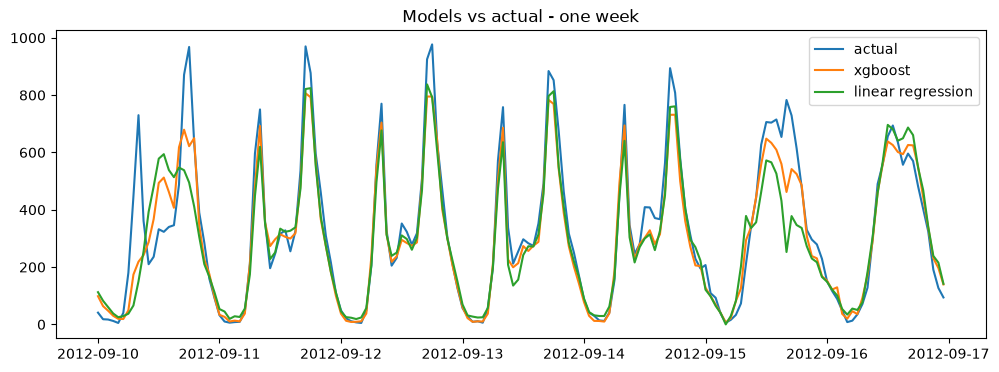

In [7]:
week = test_out.loc["2012-09-10":"2012-09-16"]

plt.figure(figsize=(12, 4))
plt.plot(week["cnt"], label="actual")
plt.plot(week["pred_xgb"], label="xgboost")
plt.plot(week["pred_linear"], label="linear regression")
plt.legend()
plt.title("Models vs actual - one week")
plt.savefig("../results/models_week.png")
plt.show()

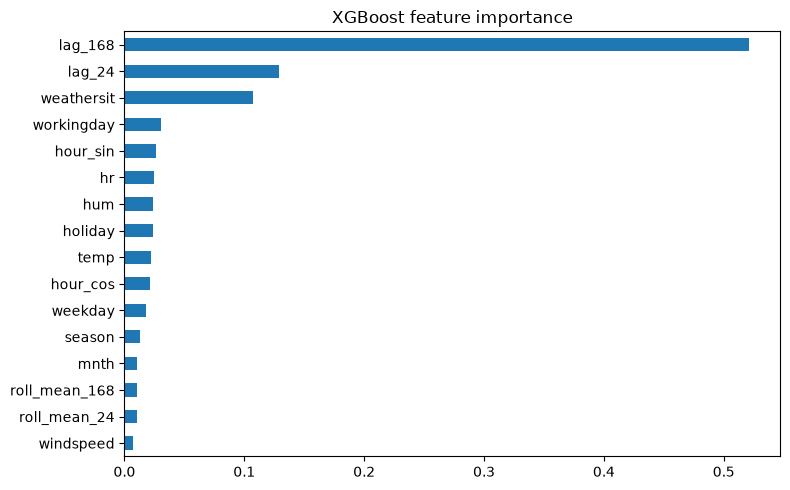

In [8]:
importance = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values()

importance.plot(kind="barh", figsize=(8, 5))
plt.title("XGBoost feature importance")
plt.tight_layout()
plt.savefig("../results/feature_importance.png")
plt.show()

In [9]:
test_out["error"] = (test_out["cnt"] - test_out["pred_xgb"]).abs()
print(test_out["error"].resample("D").mean().sort_values(ascending=False).head(5))

datetime
2012-07-04    141.548093
2012-09-10    115.609452
2012-10-02    104.445253
2012-11-23     93.831474
2012-11-22     93.779585
Name: error, dtype: float64
